<a href="https://colab.research.google.com/github/hbprosper/dihiggs/blob/main/code/heft_prepare_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Higgs Effective Field Theory (HEFT) Study: Prepare Training Data
> Created: Feb 15, 2024 Nicola de Filippis<br>
> Updated: Feb 20, 2025 HBP protect against both negative and zero cross sections<br>

### Introduction

In this project, the physics model of interest is the Higgs effective field theory (HEFT), defined by a 5D parameter space of Wilson coefficients [1]:
\begin{align}
    \theta & = c_{hhh}, c_t, c_{tt}, c_{ggh}, c_{gghh}.
\end{align}
For this investigation, we restrict our attention to a single observable, namely, the di-Higgs mass denoted by $m_{hh}$. The Standard Model (SM) values for these parameters are $c_{hhh} = c_t = 1$, and $c_{tt} = c_{ggh} = c_{gghh} = 0$. In general, we would consider multiple observables simultaneously.

We shall use simulation-based inference to construct **confidence sets**, at confidence level (CL) $\tau$, in the HEFT and later SMEFT parameter spaces. This requires approximating $\mathbb{P}(\lambda \le \lambda_0 | \theta) = \mathbb{E}(Z | \theta)$ [2,3], which we shall do in two different ways: 1) using a multi-dimensional histogram constructed using a kdtree and 2) a machine learning (ML) model, where for a given hypothesis $H_0: \theta = \theta_0$ versus $H_1: \theta \ne \theta_0$, $\lambda_0$ is the observed value of a test statistic $\lambda$ with the property that large values of the test statistic *disfavor* the hypothesis $H_0$. 

Given the cumulative distribution function (cdf), $\mathbb{P}(\lambda \le \lambda_0 | \theta)$, a confidence set at CL $\tau$ is the set of $\theta$ values for which $\mathbb{P}(\lambda \le \lambda_0 | \theta) \leq \tau$.  By definition, a confidence set (in the simplest case in which we restrict ourselves to a single class of experiments) is an observation-dependent set of $\theta$ values which upon repeated replication of the experiment is guaranteed to include the true value of $\theta$ a fraction $\ge \tau$.


### Training data
In principle [2,3], to approximate $\mathbb{P}(\lambda \le \lambda_0 | \theta)$ we need to sample the HEFT parameter space sufficiently densely and, at every point, simulate data like the ones actually observed. However, if it is computationally infeasible to sample the parameter space densely enough, the next option is to use a sparser sampling of the parameter space and reweight existing simulated data to mimic the sampling of data at any other point $\theta$. To do this requires knowledge of the cross section per binned observables, or the differential cross section,  as a function of both the *observables* and the *parameters*; here, $m_{hh}$ and $\theta$, respectively. Therefore, one sub-goal of the project is construct a parametrization of this function.

This notebook prepares the data needed to train a model of the di-Higgs cross section as a function of $m_{hh}$ and the Wilson coefficients, $\theta$.

### References
  1. Lina Alasfar *et al.*, arXiv:2304.01968v1
  2. Ann Lee *et al.*, https://arxiv.org/abs/2107.03920
  3. Ali Al Kadhim *et al.*, https://iopscience.iop.org/article/10.1088/2632-2153/ad218e


In [12]:
# ------------------------------------------------------------------
# Google Colab setup (nothing happens when run outside Colab)
#   1. clone the dihiggs repository, which holds the data files,
#   2. install the dihiggs package, which also installs drwho,
#   3. make dihiggs/code the working directory so that the relative
#      paths used below (../data, runs/, figures/) work as they do locally.
#
# Note: on Colab the data files written by this notebook exist only
# until the runtime is shut down. heft_train.ipynb uses the copies of
# these files that are in the repository.
# ------------------------------------------------------------------
import os, sys, subprocess, importlib

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    REPO = '/content/dihiggs'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q',
                        'https://github.com/hbprosper/dihiggs.git', REPO],
                       check=True)
    # A regular (non-editable) install can be imported at once; after an
    # editable install (pip install -e) the runtime must be restarted
    # before "import dihiggs" works.
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', REPO],
                   check=True)
    importlib.invalidate_caches()
    os.chdir(f'{REPO}/code')

print(f'working directory: {os.getcwd()}')

working directory: /Users/harry/Projects/Tutorials/GitHub/dihiggs/code


In [13]:
import os, sys, shutil

# the standard module for tabular data
import pandas as pd

# the standard module for array manipulation
import numpy as np

# the standard modules for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

# update fonts
FONTSIZE = 12
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : FONTSIZE}
mp.rc('font', **font)

# use LaTeX only if it is available on this system
# (it is not available on Google Colab)
mp.rc('text', usetex=shutil.which('latex') is not None)

## Load $\texttt{POWHEG}$ data

Note 1: $\kappa_\lambda \equiv c_{hhh}$.

Note 2: The bin widths in $m_{hh}$ is 15 GeV.

In [14]:
def read_data(datafile):
    print(datafile)
    df = pd.read_csv(datafile) 
    print('\nnumber of rows read: %d\n' % len(df))
    
    # Add ID column
    df['ID'] = np.linspace(0, len(df)-1, len(df)).astype(int)
    
    # Randomly shuffle order of rows in dataframe
    df = df.sample(frac=1).reset_index(drop=True)
    return df

In [15]:
!ls ../data

heft_wide_gauss_testdata_13TeV.csv     powheg_total_gauss_params_13TeV.csv.gz
heft_wide_gauss_traindata_13TeV.csv.gz


In [16]:
datafile = '../data/powheg_total_gauss_params_13TeV.csv.gz'
dfBP = read_data(datafile)
dfBP[:5]

../data/powheg_total_gauss_params_13TeV.csv.gz

number of rows read: 4999



,klambda,CT,CTT,CGHH,CGGHH,0,1,2,3,4,...,91,92,93,94,95,96,97,98,99,ID
0,4.883976,-0.864709,-1.132614,-1.384006,0.344835,0.0,0.0,0.0,0.0,0.0,...,0.000327,0.000457,0.000131,0.000261,0.000196,0.000457,0.000261,0.000131,0.000065,1577
1,-2.370850,0.947544,-1.368832,-0.916678,-4.165224,0.0,0.0,0.0,0.0,0.0,...,0.011715,0.010696,0.009677,0.014261,0.010696,0.010951,0.011969,0.011969,0.006112,799
2,4.909186,0.391809,2.752422,-1.248194,3.653164,0.0,0.0,0.0,0.0,0.0,...,0.013772,0.010971,0.009570,0.008170,0.008637,0.009570,0.007236,0.006536,0.007003,356
3,2.174473,1.167984,-6.427370,2.573832,-0.914621,0.0,0.0,0.0,0.0,0.0,...,0.005442,0.006462,0.004761,0.003061,0.005442,0.003401,0.004081,0.002381,0.002721,1778
4,-4.933608,1.890140,0.034784,-0.730673,0.587782,0.0,0.0,0.0,0.0,0.0,...,0.000554,0.000475,0.000237,0.000316,0.000277,0.000475,0.000316,0.000356,0.000277,2842


## Convert to $\texttt{numpy}$ arrays
 1. Get Wilson coefficients and cross sections / bin
 2. Protect against negative cross sections
 3. Pick cross sections from bin 17 (first non-zero bin) to 96

In [17]:
def get_column_names(df, first='17', last='96'):
    # get column names
    columns = list(df.columns)
    params  = columns[0:5]
    
    firstbin= columns.index(first)
    lastbin = columns.index(last)
    
    bins = columns[firstbin:lastbin+1]
    return params, bins

params, bins = get_column_names(dfBP)

params, bins[0], bins[-1], len(bins)

(['klambda', 'CT', 'CTT', 'CGHH', 'CGGHH'], '17', '96', 80)

In [18]:
# get Wilson coefficients
wilson = dfBP[params].to_numpy().astype(np.float32)
print(wilson.shape)

# get cross section data
BP = dfBP[bins].to_numpy().astype(np.float32)
print(BP.shape)

print(f'''
cross section/bin 

    min:  {BP.min():8.3f} pb
    max:  {BP.max():8.3f} pb
    mean: {BP.mean():8.3f} pb
    std:  {BP.std():8.3f} pb
    ''')
INDEX = dfBP.ID
BP.shape, INDEX.shape, INDEX[:10]

(4999, 5)
(4999, 80)

cross section/bin 

    min:     0.000 pb
    max:    31.680 pb
    mean:    0.109 pb
    std:     0.511 pb
    


((4999, 80),
 (4999,),
 0    1577
 1     799
 2     356
 3    1778
 4    2842
 5    2000
 6    3839
 7    3409
 8    1371
 9    2405
 Name: ID, dtype: int64)

## Save first 1000 spectra for testing

In [19]:
# Place data in a dictionary
START = 1000

dmap = {'ID': INDEX[:START],
        'klambda': wilson.T[0][:START],
        'CT': wilson.T[1][:START],
        'CTT': wilson.T[2][:START], 
        'CGGH': wilson.T[3][:START], 
        'CGGHH': wilson.T[4][:START]}

# Add spectra
dmap.update( {key: BP.T[i][:START] for i, key in enumerate(bins)} )

# Save to a csv file
df = pd.DataFrame(dmap)
df.to_csv('../data/heft_wide_gauss_testdata_13TeV.csv', index=False)

len(df), df[:5]

(1000,
      ID   klambda        CT       CTT      CGGH     CGGHH        17        18  \
 0  1577  4.883976 -0.864709 -1.132614 -1.384006  0.344835  0.203584  0.233255   
 1   799 -2.370850  0.947544 -1.368832 -0.916678 -4.165224  0.231749  0.307641   
 2   356  4.909186  0.391809  2.752422 -1.248194  3.653164  0.106208  0.167831   
 3  1778  2.174474  1.167984 -6.427370  2.573832 -0.914621  0.090468  0.157468   
 4  2842 -4.933608  1.890140  0.034784 -0.730673  0.587782  0.053642  0.064007   
 
          19        20  ...        87        88        89        90        91  \
 0  0.218746  0.196460  ...  0.000261  0.000327  0.000131  0.000196  0.000327   
 1  0.337946  0.372072  ...  0.010696  0.012988  0.016299  0.016554  0.011715   
 2  0.219885  0.251864  ...  0.007936  0.010971  0.012138  0.010504  0.013772   
 3  0.218347  0.286367  ...  0.005102  0.005782  0.005782  0.004761  0.005442   
 4  0.065747  0.069743  ...  0.000514  0.000356  0.000316  0.000554  0.000554   
 
          9

## Save diced and shuffled spectra to a csv file

Format: $k_{lambda}$, $c_{t}$,$c_{tt}$, $c_{ggh}$, $c_{ggh}$, $m_{hh}$, $\sigma$

In [20]:
# compute mid-points of di-Higgs mass bins, with the mass range mapped to the
# unit interval
_, xbins = BP.shape
xmin = 0
xmax = xbins/100 # bin width is 0.01, which corresponds to 15 GeV

x = np.linspace(xmin, xmax, xbins+1)
# x[1:] = x[1], x[2] ...,x[n-1]
# x[:-1]= x[0], x[1],...,x[n-2]
x = (x[1:]+x[:-1])/2

# --------------------------------------------------------------------
# Fill list with training data 
# IMPORTANT: Skip first "START" spectra, since they are used later for
# final assessment
# --------------------------------------------------------------------
data  = []
for ii, params, spectrum in zip(INDEX[START:], wilson[START:], BP[START:]):
    p = list(params)        
    d = []
    for mhh, sigma in zip(x, spectrum):
        d = [ii]+p+[mhh, sigma] # klambda, CT, CTT, CGGH, CGGHH, MHH, SIGMA
        data.append(d)

# keep xsec > 0
data   = np.array(data)
select = data.T[-1] > 0
data   = data[select]

# randomly shuffle rows
np.random.shuffle(data)
print(len(data))
print(f'training data size: {len(data):5d}')

# create dataframe
data = data.T  # transpose to shape (5, N)
df = pd.DataFrame(
    {'ID':       data[0].astype(int), 
     'klambda':  data[1],
     'CT':       data[2],
     'CTT':      data[3], 
     'CGGH':     data[4], 
     'CGGHH':    data[5], 
     'mhh':      data[6], 
     'sigma':    data[7]})

# save training data to a csv file
df.to_csv('../data/heft_wide_gauss_traindata_13TeV.csv.gz', index=False)

df

318072
training data size: 318072


,ID,klambda,CT,CTT,CGGH,CGGHH,mhh,sigma
0,4564,-5.762572,-0.515201,-0.134606,-0.461229,-0.881687,0.555,0.000947
1,2003,3.211057,5.074254,-0.214968,3.836754,1.048360,0.525,0.014196
2,1436,2.155230,-0.794218,-2.770548,0.984267,-3.442105,0.515,0.023730
3,4552,1.354082,0.690110,2.394794,1.901119,-0.217804,0.285,0.017420
4,1472,5.668739,0.657330,-0.150877,1.879959,2.920453,0.525,0.015264
...,...,...,...,...,...,...,...,...
318067,3584,5.679109,-3.267910,-2.553776,1.695365,0.798389,0.135,0.894712
318068,2059,0.033930,-0.142241,0.304009,-3.334332,1.855770,0.785,0.002033
318069,3888,7.887311,0.008643,-2.772400,0.486709,-4.445992,0.135,0.430005
318070,1044,-5.406513,-1.789734,2.426347,0.749006,0.909961,0.525,0.004832


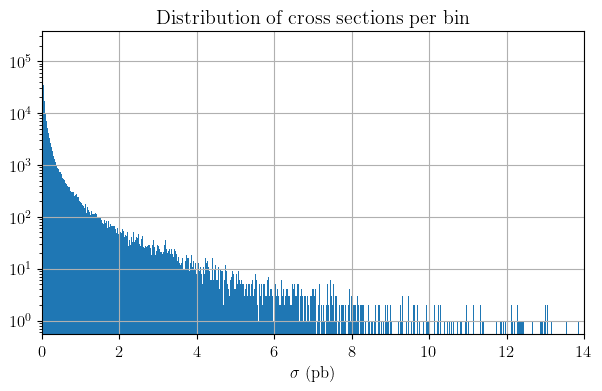

In [21]:
scale = 9/16
width = 7
fig = plt.figure(figsize=(width, width*scale))
plt.yscale('log')
plt.grid()
xmin, xmax = 0, 14
plt.xlim(xmin, xmax)
plt.xlabel(r'$\sigma$ (pb)')
plt.title('Distribution of cross sections per bin')
plt.hist(df.sigma, bins=560, range=(xmin, xmax))
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/xsection_dist.png')